# **Mapping short-let pressure in Bristol: A neighbourhood analysis of Airbnb listings**

# EDA objectives 

**Core question:** 

Where in Bristol are professional short-let operators concentrated, and how do their listings differ from those of casual hosts?

**Our definitions:**

- Operator listing: the host has 3 or more listings in this dataset. The sensitivity check uses 5 or more.
- Casual listing: the host has 1 or 2 listings.
- Concentration: the share of an area’s listings that are operator listings.

Main analysis subset: active listings (2,561). The robustness check uses current-scrape listings only (2,227).

**The questions we are exploring:**

H1: concentration varies by area.

The operator share is not the same across the 34 neighbourhoods.

- Null: any differences are no bigger than chance.
- Test: chi-square on area against operator status. Areas with very few listings may need combining.
- Charts: V2 (bar) and V3 (map).

H2: operator listings behave differently.

Compared with casual hosts, operator listings have higher annual availability and different minimum-stay requirements, as full-time commercial lettings would.

- Null: no difference.
- Test: Mann-Whitney on availability_365 and minimum_nights, reported with an effect size. Rank-based, because both are heavily skewed.
- Charts: V4 and V5.

H3: operator listings are rated differently.

Review scores differ between operator and casual listings. An early check suggested operators score lower.
- Null: no difference.
- Test: Mann-Whitney on review_scores_rating, with an effect size.
- Caveat: this uses only the 2,644 reviewed listings, so it describes reviewed listings, not all of them.
- Chart: V6.

**Process steps**

**Inputs**

# Change working directory

In [1]:
import os
current_dir = os.getcwd()
current_dir

'c:\\Users\\chheb\\OneDrive\\Documents\\Programming\\Mapping_Short_Let-Pressure_in_Bristol\\jupyter_notebooks'

In [2]:
os.chdir(os.path.dirname(current_dir))
print("You set a new current directory")

You set a new current directory


In [3]:
current_dir = os.getcwd()
current_dir

'c:\\Users\\chheb\\OneDrive\\Documents\\Programming\\Mapping_Short_Let-Pressure_in_Bristol'

# Import transformed data

In [4]:
import json
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy import stats

In [5]:
df = pd.read_csv("data/processed/listings_clean.csv", dtype={"id": str},
                 parse_dates=["first_review", "last_review"])
print(df.shape) 

(2932, 51)


# Exploring the data


## Neighbourhood table ##

**Purpose.** Hypothesis H1 and the map and bar charts need one row per neighbourhood. This table summarises the active listings (2,561) for each of the 34 areas, using the main-analysis subset decided in the transformation stage.

**Columns.** Listing counts, operator share at 3+ and 5+ listings, entire-home share, and median availability, minimum stay and rating.

**Checks.** 34 areas, 2,561 listings in total, and an overall operator share that matches the active-only figure from step 2 (about 42%).

**Caution.** [N] areas have fewer than 30 listings, so their shares are unstable. They are flagged in `small_area` and shown with their counts in the charts. The 30-listing cut-off is a judgement.

In [ ]:
active = df[df["is_active"]]            
g = active.groupby("neighbourhood_cleansed")

area = pd.DataFrame({
    "listings": g.size(),
    "operator_listings": g["is_operator"].sum(),
    "operator_share": g["is_operator"].mean(),
    "operator_share_5": g["is_operator_5"].mean(),
    "entire_home_share": g["is_entire_home"].mean(),
    "median_availability_365": g["availability_365"].median(),
    "median_min_nights": g["minimum_nights"].median(),
    "median_rating": g["review_scores_rating"].median(),
})
area["all_listings"] = df.groupby("neighbourhood_cleansed").size()    
area["small_area"] = area["listings"] < 30                            
area = area.round(3)




In [9]:
print(len(area))                                                       
print(area["listings"].sum())                                          
print((area["operator_listings"].sum() / area["listings"].sum()).round(3))   
print("Small areas:", area["small_area"].sum())                        

area.sort_values("operator_share", ascending=False).head(10)

34
2561
0.42
Small areas: 5


,listings,operator_listings,operator_share,operator_share_5,entire_home_share,median_availability_365,median_min_nights,median_rating,all_listings,small_area
neighbourhood_cleansed,,,,,,,,,,
Central,231,146,0.632,0.515,0.853,281.0,1.0,4.720,254,False
Clifton Down,166,102,0.614,0.476,0.886,264.5,2.0,4.835,176,False
Lawrence Hill,119,70,0.588,0.513,0.807,260.0,1.0,4.750,142,False
Hotwells & Harbourside,104,59,0.567,0.510,0.913,294.0,2.0,4.750,111,False
Horfield,76,42,0.553,0.382,0.487,198.5,2.0,4.840,83,False
Cotham,112,54,0.482,0.357,0.741,209.5,2.0,4.830,130,False
Clifton,173,78,0.451,0.364,0.931,246.0,2.0,4.810,205,False
Southville,133,58,0.436,0.353,0.692,155.0,2.0,4.880,153,False
Ashley,273,118,0.432,0.311,0.700,160.0,2.0,4.870,314,False


This table shows us three important things for our analysis straight away:

- The spread is large. Operator share is 63.2% in Central and 61.4% in Clifton Down, against a Bristol average of about 42%. This already supports the idea behind H1, though it needs confirming through the chi-square test.
- Stockwood is an example of how small-area could be misleading. It sits in the top ten at 42.9%, but that is 6 of 14 listings. One more or fewer operator listing moves it by about 7 points. This is why V2 shows the count for each bar.
- Operators aren’t only entire homes. Horfield has a 55.3% operator share but only 48.7% entire homes, against 85% to 93% in the other top areas. A different kind of operator activity may be happening there.

## V0: Distributions ##

We need to explore whether the main listing measures evenly spread, or dominated by a few extreme values. The answer is crucial for deciding which summaries and statistical tests are appropriate for the rest of the analysis.

I plotted a histogram for each of four measures across the 2,561 active listings: 
- `price` 
- `minimum_nights`
- `availability_365`
- `calculated_host_listings_count` 

On each, the mean (dashed line) and median (solid line) are marked, and a table reports the mean, median and skewness.

I choose these four measures because they are the ones the hypotheses and the model will rely on. Price and availability describe how a listing is run, minimum stay is tested in H2, and the host listing count defines an operator.


                                  mean  median  skewness
price                           157.22   130.0      5.95
minimum_nights                    3.54     2.0     14.75
availability_365                202.20   239.0     -0.25
calculated_host_listings_count   13.54     2.0      3.10


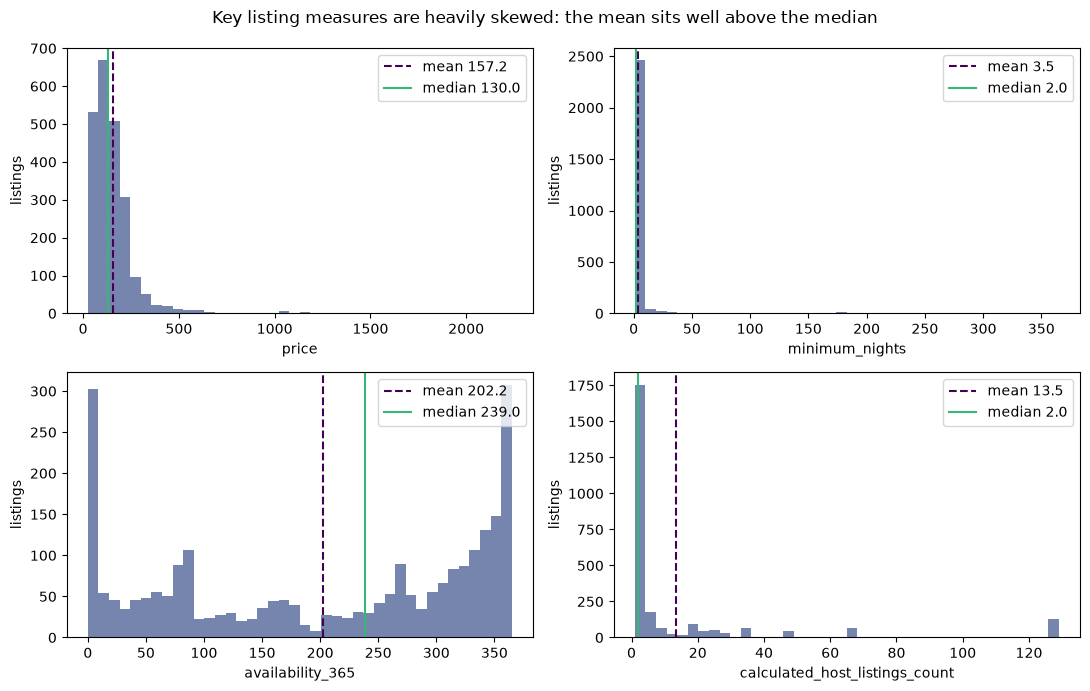

In [ ]:
skew_cols = ["price", "minimum_nights", "availability_365", "calculated_host_listings_count"]
print(pd.DataFrame({"mean": active[skew_cols].mean(),
                    "median": active[skew_cols].median(),
                    "skewness": active[skew_cols].skew()}).round(2))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), skew_cols):
    data = active[col].dropna()
    ax.hist(data, bins=40, color="#3b528b", alpha=0.7)
    ax.axvline(data.mean(), color="#440154", linestyle="--", label=f"mean {data.mean():.1f}")
    ax.axvline(data.median(), color="#35b779", linestyle="-", label=f"median {data.median():.1f}")
    ax.set_xlabel(col); ax.set_ylabel("listings"); ax.legend()
fig.suptitle("Key listing measures are skewed: the mean sits well above the median")
plt.tight_layout()
plt.show()


- Three of the four measures are strongly right-skewed (skewness well above 1). A small number of extreme values pull the mean above the median: a few very expensive properties, a few listings that require a month or more (up to 365 nights), and a few hosts with dozens of listings, the largest with 129.
- `availability_365` is different. Its skewness is close to zero and its mean sits slightly below its median, so it is not dominated by extreme values. [DESCRIBE what the histogram shows, for example whether listings bunch at zero or at 365 days, using the shares at 0 and 365 days.]

**What this means for the analysis**

- For skewed measures the mean is a poor summary of a typical listing, so we report medians when describing one.
- The comparisons in H2 and H3 use rank-based tests (Mann-Whitney), which compare the order of values and are not distorted by a few extremes. A t-test, which compares means, would be. For availability the case is weaker, because it is not skewed. A rank-based test is still appropriate because it does not assume the values follow a bell-shaped curve, and [CONFIRM from the histogram that availability is not bell-shaped].
- Log-transforming was considered for the skewed measures. It does not suit minimum stay, which is mostly one to three nights. Where a chart needs to show a long tail (for example price), a log axis is used and labelled.

It is important to note that skew shows that extreme values exist, not that they are errors. The extremes checked in the outlier step of our ETL process were genuine listings, so they stay in the data.

## V1: What is the market's composition? ##

Our next task is getting a clearer picture of what is the market made of. In particualr, we want to know whether operator and casual listings differ in the type of property they offer?

I used a a stacked bar chart to compare the room-type mix of operator listings (hosts with 3 or more listings, n=1,075) and casual listings (1 to 2 listings, n=1,486) among active listings. This means the two groups are comparable despite thier different sizes.

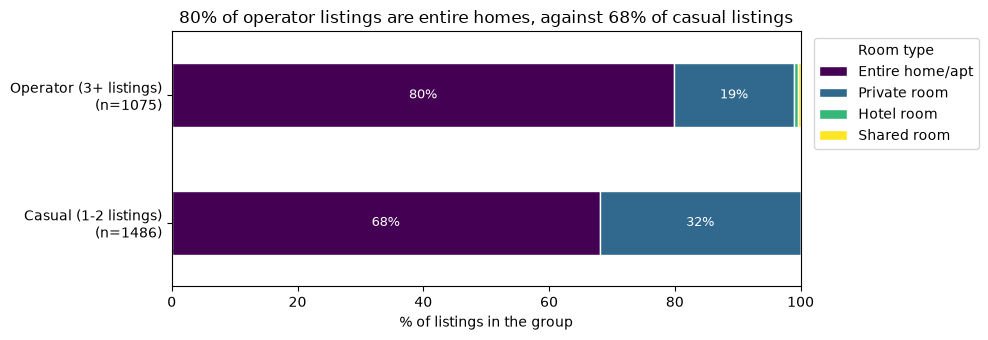

In [12]:
labels = {True: "Operator (3+ listings)", False: "Casual (1-2 listings)"}
group = active["is_operator"].map(labels)
order = ["Entire home/apt", "Private room", "Hotel room", "Shared room"]

comp = pd.crosstab(group, active["room_type"], normalize="index")[order] * 100
n = group.value_counts()

ax = comp.plot(kind="barh", stacked=True, figsize=(10, 3.5), colormap="viridis", edgecolor="white")
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v:.0f}%" if v >= 4 else "" for v in c.datavalues],
                 label_type="center", color="white", fontsize=9)

ax.set_yticklabels([f"{g}\n(n={n[g]})" for g in comp.index])
ax.set_xlabel("% of listings in the group")
ax.set_ylabel("")
op_home = comp.loc[labels[True], "Entire home/apt"]
cas_home = comp.loc[labels[False], "Entire home/apt"]
ax.set_title(f"{op_home:.0f}% of operator listings are entire homes, against {cas_home:.0f}% of casual listings")
ax.legend(title="Room type", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

  

In [13]:
comp.round(1)  

room_type,Entire home/apt,Private room,Hotel room,Shared room
is_operator,,,,
Casual (1-2 listings),68.0,32.0,0.0,0.0
Operator (3+ listings),79.9,19.0,0.7,0.5


In [14]:
active.groupby("room_type")["is_operator"].agg(["size", "mean"]).round(3)

,size,mean
room_type,,
Entire home/apt,1870,0.459
Hotel room,7,1.000
Private room,679,0.300
Shared room,5,1.000


- Entire homes make up the majority in both groups. But this definately more the case for operators, with entire homes making up 80% of thier listings (compraed to 68% of casual listings).
- Private rooms make up 19% of operator listings and 32% of casual listings.
- Hotel and shared rooms are under 1% of either group.

**What this means for Bristol City Council.** 

Operator activity is concentrated in entire homes, the property type most likely to be taken out of long-term housing. We can see that operators hold about 46 of all active entire-home listings. However,  the data cannot show whether those homes were previously rented to residents.

**Linitations:** 

The chart shows the mix within each group, not the share of each room type that operators hold. "Casual" includes hosts with two listings, and the 3-listing threshold is a judgement call. This is a description, not a test. In reality, it does not show that the difference is more than chance.

## V2: Are operators concentrated in certain areas?

An important part of our understanding of the data is seeing if professional operators are concentrated in certain areas? This is the basis of H1.

I calculated the share of active listings run by operators (hosts with 3 or more listings) in each of the 34 neighbourhoods, and ranked them. Bar labels show the number of active listings behind each share, and areas with fewer than 30 listings are shaded grey.

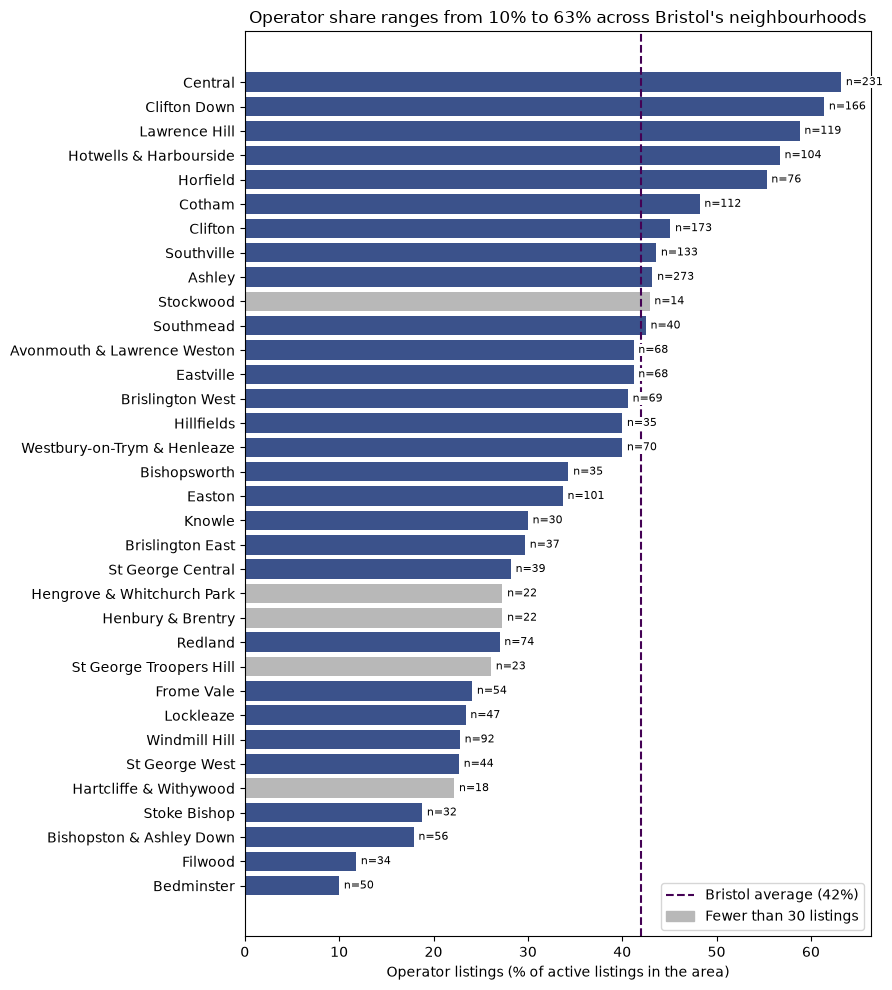

In [18]:
from matplotlib.patches import Patch

plot = area.reset_index().sort_values("operator_share")
overall = active["is_operator"].mean() * 100
lo, hi = plot["operator_share"].min() * 100, plot["operator_share"].max() * 100

fig, ax = plt.subplots(figsize=(9, 10))
colors = np.where(plot["small_area"], "#b8b8b8", "#3b528b")        # grey = fewer than 30 listings
ax.barh(plot["neighbourhood_cleansed"], plot["operator_share"] * 100, color=colors)
ax.axvline(overall, color="#440154", linestyle="--", label=f"Bristol average ({overall:.0f}%)")

for y, (share, n) in enumerate(zip(plot["operator_share"], plot["listings"])):
    ax.text(share * 100 + 0.5, y, f"n={n}", va="center", fontsize=8,
            bbox=dict(facecolor="white", edgecolor="none", pad=0.5))   # keeps labels readable over the line

ax.set_xlabel("Operator listings (% of active listings in the area)")
ax.set_title(f"Operator share ranges from {lo:.0f}% to {hi:.0f}% across Bristol's neighbourhoods")

handles, _ = ax.get_legend_handles_labels()
handles.append(Patch(color="#b8b8b8", label="Fewer than 30 listings"))
ax.legend(handles=handles)

plt.tight_layout()
plt.show()


- Operator share varies widely, from 10% in Bedminster to 63% in Central, against a Bristol average of 42%.
- Four areas (Central, Clifton Down, Lawrence Hill, Hotwells & Harbourside) have shares above 55%. Together they hold 24% of active listings but 35% of operator listings.
- Most areas are below the Bristol average. The average is pulled up by a small number of large, high-share areas.

**What this means for Bristol City Council.** 

Operator activity is not spread evenly. A small number of areas account for a disproportionate share of it, so any attention to professional short-lets would reach more of it by starting there.

**Limitations:**

- Five areas have fewer than 30 listings, and several more have 30 to 40, so their shares are unstable. The 30-listing cut-off is a judgement.
- The chart shows the size of the differences, not whether they are more than chance.
- We can show where operator listings are, but not whether they are a direct cause of housing pressure.